In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("Libraries imported successfully")

Libraries imported successfully


In [3]:
invoices = pd.read_csv("data/raw/customer_payment_invoices.csv")
customers = pd.read_csv("data/raw/customer_master.csv")

print("Invoice dataset shape:", invoices.shape)
print("Customer dataset shape:", customers.shape)

Invoice dataset shape: (36228, 25)
Customer dataset shape: (1000, 8)


In [4]:
print("INVOICE DATASET")
print("Rows:", invoices.shape[0])
print("Columns:", invoices.shape[1])

print("\nCUSTOMER DATASET")
print("Rows:", customers.shape[0])
print("Columns:", customers.shape[1])

print("\nINVOICE COLUMN NAMES")
print(invoices.columns.tolist())

INVOICE DATASET
Rows: 36228
Columns: 25

CUSTOMER DATASET
Rows: 1000
Columns: 8

INVOICE COLUMN NAMES
['invoice_id', 'customer_id', 'invoice_date', 'due_date', 'invoice_amount', 'payment_terms', 'payment_terms_days', 'discount_available', 'discount_rate', 'discount_days', 'discount_deadline', 'discount_taken', 'discount_amount', 'amount_paid', 'outstanding_balance', 'payment_date', 'payment_status', 'actual_days_to_pay', 'days_late', 'industry', 'region', 'customer_tenure_years', 'credit_limit', 'behavior_profile', 'paid_late']


In [5]:
missing_values = invoices.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Percentage Missing": (missing_values / len(invoices)) * 100
})

display(missing_summary)

,Missing Values,Percentage Missing
invoice_id,0,0.000000
customer_id,0,0.000000
invoice_date,0,0.000000
due_date,0,0.000000
invoice_amount,0,0.000000
payment_terms,0,0.000000
payment_terms_days,0,0.000000
discount_available,0,0.000000
discount_rate,0,0.000000
discount_days,0,0.000000


In [6]:
total_invoices = len(invoices)

total_invoiced = invoices["invoice_amount"].sum()
total_collected = invoices["amount_paid"].sum()
total_outstanding = invoices["outstanding_balance"].sum()

paid_invoices = invoices["payment_status"].isin(["Paid", "Paid Late"]).sum()
unpaid_invoices = total_invoices - paid_invoices

print("TOTAL INVOICES:", total_invoices)
print("TOTAL INVOICED: $", round(total_invoiced, 2))
print("TOTAL COLLECTED: $", round(total_collected, 2))
print("TOTAL OUTSTANDING: $", round(total_outstanding, 2))
print("PAID INVOICES:", paid_invoices)
print("OTHER INVOICES:", unpaid_invoices)

TOTAL INVOICES: 36228
TOTAL INVOICED: $ 149954777.25
TOTAL COLLECTED: $ 141714022.22
TOTAL OUTSTANDING: $ 7828350.23
PAID INVOICES: 34003
OTHER INVOICES: 2225


In [7]:
print(invoices["payment_status"].value_counts(dropna=False))

payment_status
Paid              34003
Open                780
Partially Paid      747
Overdue             698
Name: count, dtype: int64


In [8]:
print(invoices["paid_late"].value_counts(dropna=False))

paid_late
0.0    23856
1.0    10147
NaN     2225
Name: count, dtype: int64


In [9]:
payment_counts = paid_invoices["paid_late"].value_counts().sort_index()

plt.figure(figsize=(8, 5))
plt.bar(
    ["On Time", "Late"],
    [payment_counts.get(0, 0), payment_counts.get(1, 0)]
)

plt.title("On-Time vs Late Invoice Payments")
plt.xlabel("Payment Category")
plt.ylabel("Number of Invoices")
plt.show()

IndexError: invalid index to scalar variable.

In [10]:
paid_invoice_rows = invoices[invoices["paid_late"].notna()].copy()

print("Number of paid invoices:", len(paid_invoice_rows))

Number of paid invoices: 34003


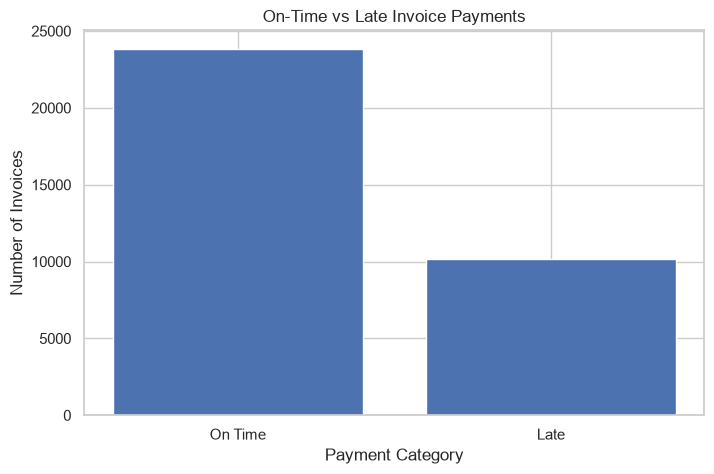

In [11]:
payment_counts = paid_invoice_rows["paid_late"].value_counts().sort_index()

plt.figure(figsize=(8, 5))

plt.bar(
    ["On Time", "Late"],
    [
        payment_counts.get(0, 0),
        payment_counts.get(1, 0)
    ]
)

plt.title("On-Time vs Late Invoice Payments")
plt.xlabel("Payment Category")
plt.ylabel("Number of Invoices")

plt.show()

In [12]:
late_payment_rate = paid_invoice_rows["paid_late"].mean() * 100

print("Total paid invoices:", len(paid_invoice_rows))
print("Late payment rate:", round(late_payment_rate, 2), "%")
print("On-time payment rate:", round(100 - late_payment_rate, 2), "%")

Total paid invoices: 34003
Late payment rate: 29.84 %
On-time payment rate: 70.16 %


In [13]:
industry_analysis = paid_invoice_rows.groupby("industry").agg(
    total_invoices=("paid_late", "count"),
    late_invoices=("paid_late", "sum"),
    late_payment_rate=("paid_late", "mean"),
    average_invoice_amount=("invoice_amount", "mean")
).reset_index()

industry_analysis["late_payment_rate"] *= 100

industry_analysis = industry_analysis.sort_values(
    "late_payment_rate", ascending=False
)

display(industry_analysis.round(2))

,industry,total_invoices,late_invoices,late_payment_rate,average_invoice_amount
6,Transportation,4883,1665.0,34.10,4197.83
2,Manufacturing,5213,1713.0,32.86,4062.83
3,Professional Services,4899,1576.0,32.17,4082.07
5,Technology,5002,1442.0,28.83,4169.44
1,Healthcare,5304,1454.0,27.41,4108.71
4,Retail,4724,1264.0,26.76,4133.65
0,Construction,3978,1033.0,25.97,4192.10


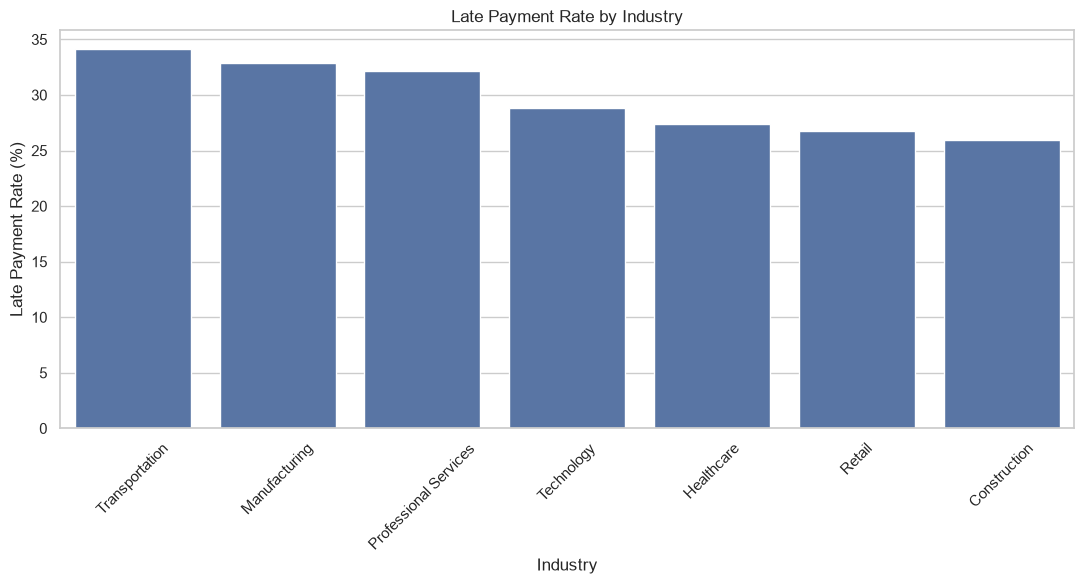

In [14]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=industry_analysis,
    x="industry",
    y="late_payment_rate"
)

plt.title("Late Payment Rate by Industry")
plt.xlabel("Industry")
plt.ylabel("Late Payment Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [15]:
industry_outstanding = invoices.groupby("industry").agg(
    total_outstanding=("outstanding_balance", "sum"),
    invoice_count=("invoice_id", "count")
).reset_index()

industry_outstanding = industry_outstanding.sort_values(
    "total_outstanding", ascending=False
)

display(industry_outstanding.round(2))

,industry,total_outstanding,invoice_count
2,Manufacturing,1271568.13,5568
5,Technology,1168957.97,5317
6,Transportation,1164406.22,5225
1,Healthcare,1096805.63,5643
3,Professional Services,1091441.27,5216
4,Retail,1082730.44,5033
0,Construction,952440.57,4226


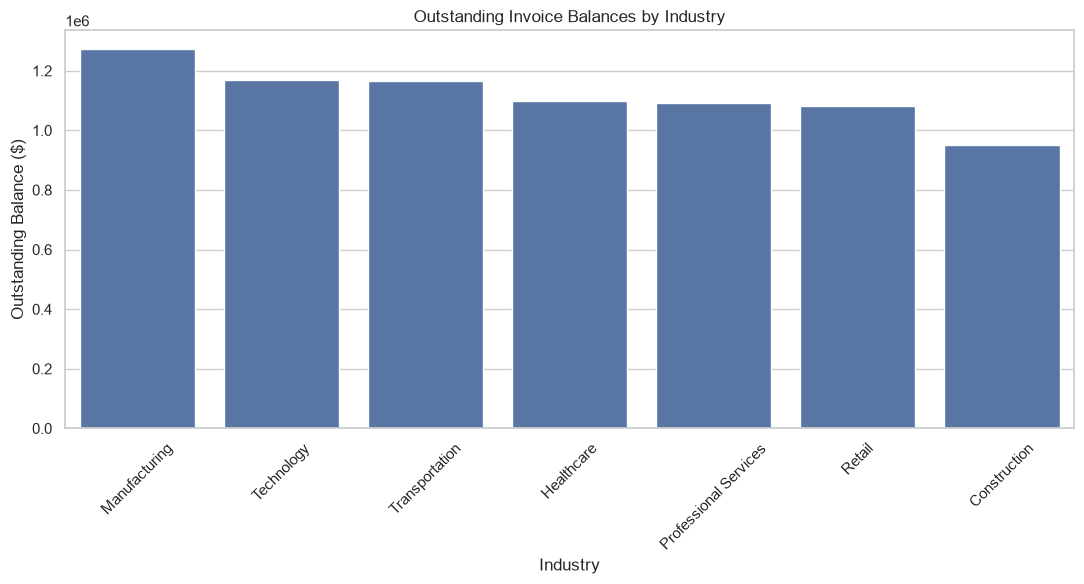

In [16]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=industry_outstanding,
    x="industry",
    y="total_outstanding"
)

plt.title("Outstanding Invoice Balances by Industry")
plt.xlabel("Industry")
plt.ylabel("Outstanding Balance ($)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [17]:
customer_analysis = paid_invoice_rows.groupby("customer_id").agg(
    total_paid_invoices=("invoice_id", "count"),
    late_invoices=("paid_late", "sum"),
    late_payment_rate=("paid_late", "mean"),
    average_days_to_pay=("actual_days_to_pay", "mean"),
    average_invoice_amount=("invoice_amount", "mean")
).reset_index()

customer_analysis["late_payment_rate"] *= 100

customer_analysis = customer_analysis.sort_values(
    "late_payment_rate", ascending=False
)

display(customer_analysis.head(15).round(2))

,customer_id,total_paid_invoices,late_invoices,late_payment_rate,average_days_to_pay,average_invoice_amount
660,CUST0661,32,27.0,84.38,60.34,3337.78
405,CUST0406,30,25.0,83.33,65.43,4048.93
646,CUST0647,30,25.0,83.33,65.07,3904.22
970,CUST0971,29,24.0,82.76,58.93,3154.81
214,CUST0215,40,33.0,82.50,59.95,4084.69
458,CUST0459,28,23.0,82.14,58.11,4263.03
350,CUST0351,39,32.0,82.05,57.87,3804.15
623,CUST0624,39,32.0,82.05,56.85,4563.72
359,CUST0360,33,27.0,81.82,61.06,5075.66
653,CUST0654,38,31.0,81.58,57.53,4440.85


In [18]:
high_risk_customers = customer_analysis[
    (customer_analysis["late_payment_rate"] >= 70) &
    (customer_analysis["total_paid_invoices"] >= 5)
]

display(high_risk_customers.head(15).round(2))

,customer_id,total_paid_invoices,late_invoices,late_payment_rate,average_days_to_pay,average_invoice_amount
660,CUST0661,32,27.0,84.38,60.34,3337.78
405,CUST0406,30,25.0,83.33,65.43,4048.93
646,CUST0647,30,25.0,83.33,65.07,3904.22
970,CUST0971,29,24.0,82.76,58.93,3154.81
214,CUST0215,40,33.0,82.50,59.95,4084.69
458,CUST0459,28,23.0,82.14,58.11,4263.03
350,CUST0351,39,32.0,82.05,57.87,3804.15
623,CUST0624,39,32.0,82.05,56.85,4563.72
359,CUST0360,33,27.0,81.82,61.06,5075.66
653,CUST0654,38,31.0,81.58,57.53,4440.85


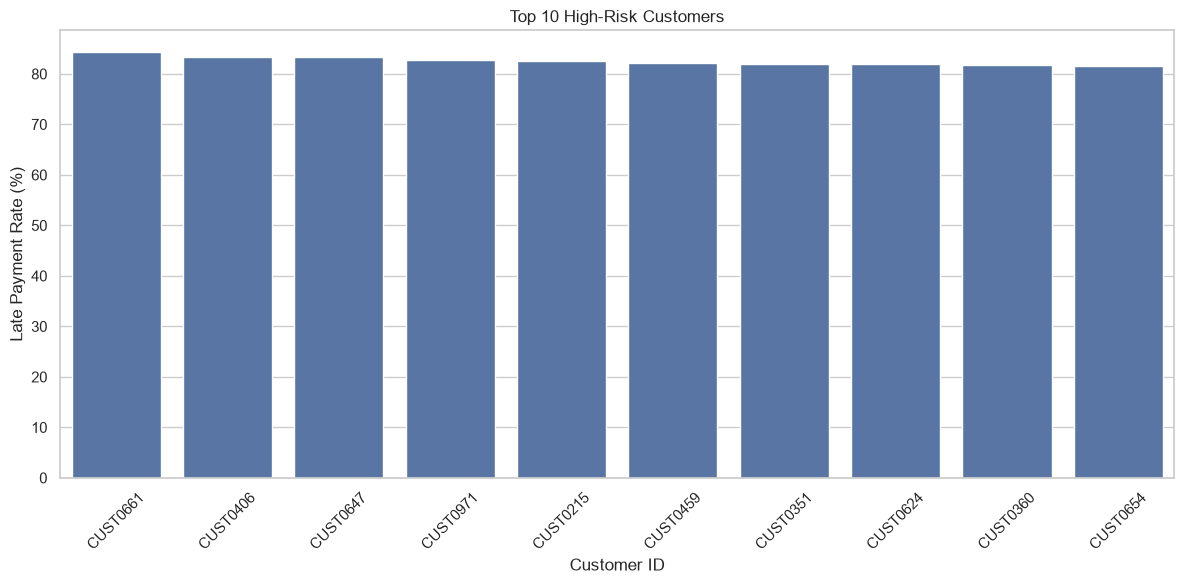

In [19]:
top_customers = high_risk_customers.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_customers,
    x="customer_id",
    y="late_payment_rate"
)

plt.title("Top 10 High-Risk Customers")
plt.xlabel("Customer ID")
plt.ylabel("Late Payment Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [20]:
discount_analysis = paid_invoice_rows.groupby("discount_taken").agg(
    total_invoices=("invoice_id", "count"),
    average_days_to_pay=("actual_days_to_pay", "mean"),
    average_invoice_amount=("invoice_amount", "mean"),
    average_days_late=("days_late", "mean")
).reset_index()

display(discount_analysis.round(2))

,discount_taken,total_invoices,average_days_to_pay,average_invoice_amount,average_days_late
0,False,28145,44.84,4136.06,4.93
1,True,5858,8.16,4117.07,-30.45


In [21]:
terms_analysis = paid_invoice_rows.groupby("payment_terms").agg(
    total_invoices=("invoice_id", "count"),
    average_days_to_pay=("actual_days_to_pay", "mean"),
    late_payment_rate=("paid_late", "mean"),
    average_invoice_amount=("invoice_amount", "mean")
).reset_index()

terms_analysis["late_payment_rate"] *= 100

display(terms_analysis.round(2))

,payment_terms,total_invoices,average_days_to_pay,late_payment_rate,average_invoice_amount
0,1/10 Net 45,3509,30.18,22.03,4095.70
1,2/10 Net 30,5018,22.74,22.26,4201.70
2,2/15 Net 45,3281,31.14,21.73,4144.28
3,Net 30,12058,34.23,33.96,4118.16
4,Net 45,5091,49.30,34.47,4084.28
5,Net 60,5046,64.22,33.57,4166.50


In [22]:
total_discount_cost = invoices["discount_amount"].sum()

total_invoiced = invoices["invoice_amount"].sum()

discount_percentage = (total_discount_cost / total_invoiced) * 100

print("Total discount cost: $", round(total_discount_cost, 2))
print("Total invoiced amount: $", round(total_invoiced, 2))
print("Discount cost as percentage of invoices:", round(discount_percentage, 2), "%")

Total discount cost: $ 412404.8
Total invoiced amount: $ 149954777.25
Discount cost as percentage of invoices: 0.28 %


In [23]:
discount_eligible = invoices[
    invoices["discount_percentage"] > 0
]

discount_used = discount_eligible[
    discount_eligible["discount_taken"] == True
]

adoption_rate = len(discount_used) / len(discount_eligible) * 100

print("Discount-eligible invoices:", len(discount_eligible))
print("Discounts actually used:", len(discount_used))
print("Discount adoption rate:", round(adoption_rate, 2), "%")

KeyError: 'discount_percentage'

In [24]:
print(invoices.columns.tolist())

['invoice_id', 'customer_id', 'invoice_date', 'due_date', 'invoice_amount', 'payment_terms', 'payment_terms_days', 'discount_available', 'discount_rate', 'discount_days', 'discount_deadline', 'discount_taken', 'discount_amount', 'amount_paid', 'outstanding_balance', 'payment_date', 'payment_status', 'actual_days_to_pay', 'days_late', 'industry', 'region', 'customer_tenure_years', 'credit_limit', 'behavior_profile', 'paid_late']


In [25]:
discount_eligible = invoices[
    invoices["discount_available"] == True
]

discount_used = discount_eligible[
    discount_eligible["discount_taken"] == True
]

adoption_rate = (
    len(discount_used) / len(discount_eligible)
) * 100

print("Discount-eligible invoices:", len(discount_eligible))
print("Invoices where discount was used:", len(discount_used))
print("Discount adoption rate:", round(adoption_rate, 2), "%")

Discount-eligible invoices: 12453
Invoices where discount was used: 5858
Discount adoption rate: 47.04 %


In [26]:
invoices["invoice_date"] = pd.to_datetime(invoices["invoice_date"])

invoices["invoice_month"] = invoices["invoice_date"].dt.to_period("M")

monthly_analysis = invoices.groupby("invoice_month").agg(
    total_invoiced=("invoice_amount", "sum"),
    total_collected=("amount_paid", "sum"),
    total_outstanding=("outstanding_balance", "sum"),
    invoice_count=("invoice_id", "count")
).reset_index()

monthly_analysis["invoice_month"] = monthly_analysis["invoice_month"].astype(str)

display(monthly_analysis.head(10))

,invoice_month,total_invoiced,total_collected,total_outstanding,invoice_count
0,2023-10,453112.42,441021.68,10449.06,118
1,2023-11,3918097.46,3809927.77,96589.79,979
2,2023-12,4340196.36,4243725.54,83597.95,1022
3,2024-01,4614960.54,4487174.76,112885.32,1061
4,2024-02,3809502.10,3663798.97,135389.90,917
5,2024-03,4620182.96,4449463.70,157832.80,1039
6,2024-04,4137113.16,4049505.78,73982.21,1013
7,2024-05,4347388.43,4247233.83,88080.62,1011
8,2024-06,4138622.39,4048034.80,78780.24,1007
9,2024-07,4022135.82,3964105.20,48717.85,1007


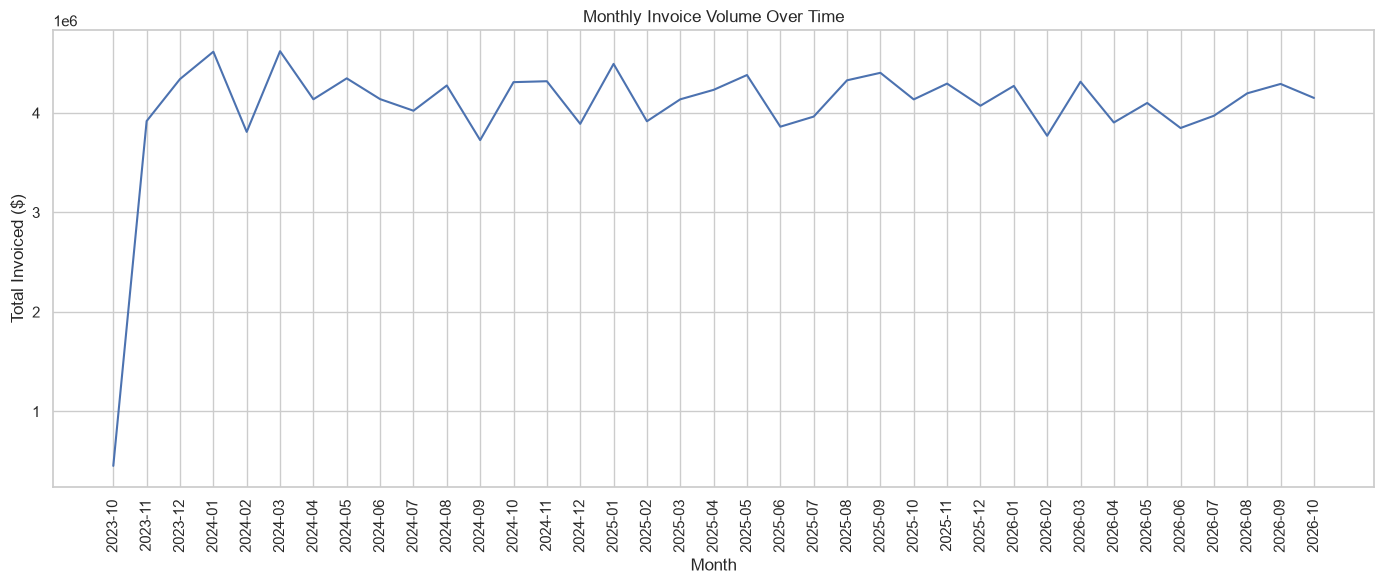

In [27]:
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_analysis,
    x="invoice_month",
    y="total_invoiced"
)

plt.title("Monthly Invoice Volume Over Time")
plt.xlabel("Month")
plt.ylabel("Total Invoiced ($)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

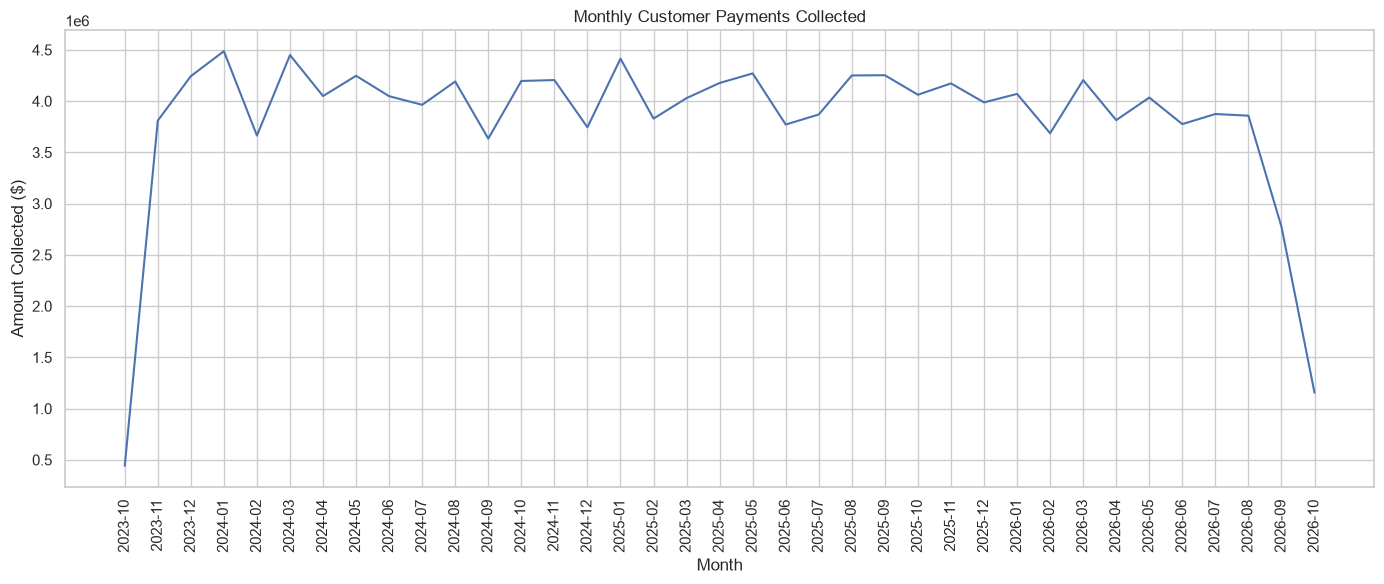

In [28]:
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_analysis,
    x="invoice_month",
    y="total_collected"
)

plt.title("Monthly Customer Payments Collected")
plt.xlabel("Month")
plt.ylabel("Amount Collected ($)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

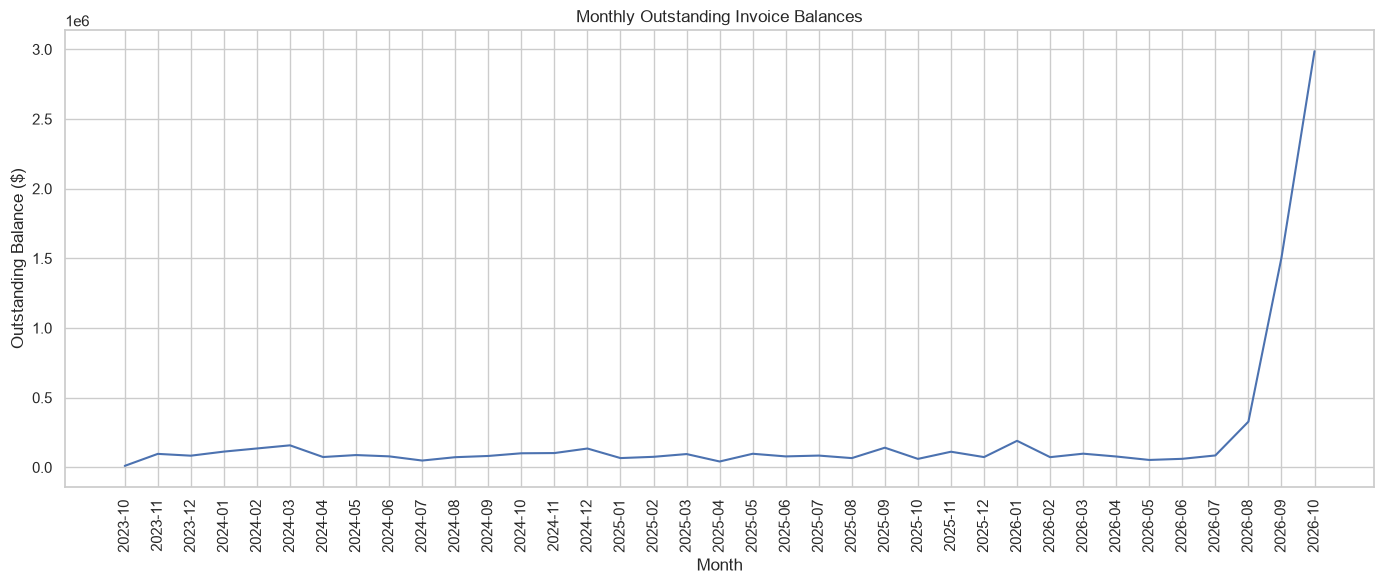

In [29]:
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_analysis,
    x="invoice_month",
    y="total_outstanding"
)

plt.title("Monthly Outstanding Invoice Balances")
plt.xlabel("Month")
plt.ylabel("Outstanding Balance ($)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [30]:
print("Dataset shape:", invoices.shape)

print("\nMissing values:")
display(invoices.isnull().sum())

print("\nDuplicate invoice IDs:")
print(invoices["invoice_id"].duplicated().sum())

print("\nData types:")
display(invoices.dtypes)

Dataset shape: (36228, 26)

Missing values:


invoice_id                   0
customer_id                  0
invoice_date                 0
due_date                     0
invoice_amount               0
payment_terms                0
payment_terms_days           0
discount_available           0
discount_rate                0
discount_days                0
discount_deadline        23775
discount_taken               0
discount_amount              0
amount_paid                  0
outstanding_balance          0
payment_date              1478
payment_status               0
actual_days_to_pay        2225
days_late                 2225
industry                     0
region                       0
customer_tenure_years        0
credit_limit                 0
behavior_profile             0
paid_late                 2225
invoice_month                0
dtype: int64


Duplicate invoice IDs:
0

Data types:


invoice_id                          str
customer_id                         str
invoice_date             datetime64[us]
due_date                            str
invoice_amount                  float64
payment_terms                       str
payment_terms_days                int64
discount_available                 bool
discount_rate                   float64
discount_days                     int64
discount_deadline                   str
discount_taken                     bool
discount_amount                 float64
amount_paid                     float64
outstanding_balance             float64
payment_date                        str
payment_status                      str
actual_days_to_pay              float64
days_late                       float64
industry                            str
region                              str
customer_tenure_years           float64
credit_limit                      int64
behavior_profile                    str
paid_late                       float64


In [31]:
date_columns = [
    "invoice_date",
    "due_date",
    "discount_deadline",
    "payment_date"
]

for col in date_columns:
    invoices[col] = pd.to_datetime(invoices[col], errors="coerce")

print(invoices[date_columns].dtypes)

invoice_date         datetime64[us]
due_date             datetime64[us]
discount_deadline    datetime64[us]
payment_date         datetime64[us]
dtype: object


In [32]:
financial_columns = [
    "invoice_amount",
    "discount_amount",
    "amount_paid",
    "outstanding_balance"
]

print(invoices[financial_columns].dtypes)

invoice_amount         float64
discount_amount        float64
amount_paid            float64
outstanding_balance    float64
dtype: object


In [33]:
print("Invoices with zero or negative amounts:")
print((invoices["invoice_amount"] <= 0).sum())

print("\nInvoices with negative outstanding balances:")
print((invoices["outstanding_balance"] < 0).sum())

Invoices with zero or negative amounts:
0

Invoices with negative outstanding balances:
0


In [34]:
model_data = invoices.copy()

model_data["invoice_year"] = model_data["invoice_date"].dt.year

model_data["invoice_month"] = model_data["invoice_date"].dt.month

model_data["invoice_quarter"] = model_data["invoice_date"].dt.quarter

model_data["invoice_day_of_week"] = model_data["invoice_date"].dt.dayofweek

model_data["invoice_amount_log"] = np.log1p(model_data["invoice_amount"])

model_data["invoice_to_credit_limit_ratio"] = (
    model_data["invoice_amount"] / model_data["credit_limit"]
)

model_data["has_early_payment_discount"] = (
    model_data["discount_available"].astype(int)
)

display(model_data.head())

/var/folders/w5/hwbdb_px3f93y8xcpgw8258c0000gn/T/ipykernel_9710/64091549.py:9: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  model_data["invoice_day_of_week"] = model_data["invoice_date"].dt.dayofweek


,invoice_id,customer_id,invoice_date,due_date,invoice_amount,payment_terms,payment_terms_days,discount_available,discount_rate,discount_days,...,credit_limit,behavior_profile,paid_late,invoice_month,invoice_year,invoice_quarter,invoice_day_of_week,invoice_amount_log,invoice_to_credit_limit_ratio,has_early_payment_discount
0,INV0000001,CUST0001,2023-10-29,2023-11-28,13905.09,2/10 Net 30,30,True,0.02,10,...,10000,Mixed,0.0,10,2023,4,6,9.540082,1.390509,1
1,INV0000002,CUST0001,2023-11-30,2024-01-14,7221.41,1/10 Net 45,45,True,0.01,10,...,10000,Mixed,0.0,11,2023,4,3,8.884944,0.722141,1
2,INV0000003,CUST0001,2024-01-14,2024-02-13,2892.27,Net 30,30,False,0.00,0,...,10000,Mixed,1.0,1,2024,1,6,7.970143,0.289227,0
3,INV0000004,CUST0001,2024-03-13,2024-04-12,9599.24,Net 30,30,False,0.00,0,...,10000,Mixed,1.0,3,2024,1,2,9.169543,0.959924,0
4,INV0000005,CUST0001,2024-05-04,2024-06-03,2484.40,Net 30,30,False,0.00,0,...,10000,Mixed,0.0,5,2024,2,5,7.818189,0.248440,0


In [35]:
new_features = [
    "invoice_year",
    "invoice_month",
    "invoice_quarter",
    "invoice_day_of_week",
    "invoice_amount_log",
    "invoice_to_credit_limit_ratio",
    "has_early_payment_discount"
]

display(model_data[new_features].describe().round(2))

,invoice_year,invoice_month,invoice_quarter,invoice_day_of_week,invoice_amount_log,invoice_to_credit_limit_ratio,has_early_payment_discount
count,36228.00,36228.00,36228.00,36228.00,36228.00,36228.00,36228.00
mean,2024.82,6.51,2.51,3.00,8.01,0.14,0.34
std,0.90,3.46,1.12,1.99,0.80,0.23,0.47
min,2023.00,1.00,1.00,0.00,5.30,0.00,0.00
25%,2024.00,4.00,2.00,1.00,7.47,0.03,0.00
50%,2025.00,7.00,3.00,3.00,8.00,0.06,0.00
75%,2026.00,10.00,4.00,5.00,8.54,0.15,1.00
max,2026.00,12.00,4.00,6.00,11.29,4.95,1.00


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

invoices = pd.read_csv("data/raw/customer_payment_invoices.csv")
customers = pd.read_csv("data/raw/customer_master.csv")

invoices["invoice_date"] = pd.to_datetime(invoices["invoice_date"])
invoices["payment_date"] = pd.to_datetime(invoices["payment_date"])

model_data = invoices.copy()

print("Invoices loaded:", len(invoices))
print("Customers loaded:", len(customers))

Invoices loaded: 36228
Customers loaded: 1000


In [1]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, roc_auc_score

numeric_features = [
    "invoice_amount",
    "payment_terms_days",
    "discount_rate",
    "discount_days",
    "customer_tenure_years",
    "credit_limit",
    "invoice_year",
    "invoice_month",
    "invoice_quarter",
    "invoice_day_of_week",
    "invoice_amount_log",
    "invoice_to_credit_limit_ratio",
    "history_paid_invoice_count",
    "historical_late_payment_rate",
    "historical_average_days_to_pay"
]

categorical_features = [
    "payment_terms",
    "industry",
    "region"
]

X = modeling_data[numeric_features + categorical_features]
y = modeling_data["paid_late"]

print("Input features:", X.shape)
print("Target variable:", y.shape)
print("\nTarget distribution:")
print(y.value_counts(normalize=True).round(3))

NameError: name 'modeling_data' is not defined

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, roc_auc_score

invoices = pd.read_csv("data/raw/customer_payment_invoices.csv")

invoices["invoice_date"] = pd.to_datetime(invoices["invoice_date"])
invoices["payment_date"] = pd.to_datetime(invoices["payment_date"])

model_data = invoices.copy()

model_data["invoice_year"] = model_data["invoice_date"].dt.year
model_data["invoice_month"] = model_data["invoice_date"].dt.month
model_data["invoice_quarter"] = model_data["invoice_date"].dt.quarter
model_data["invoice_day_of_week"] = model_data["invoice_date"].dt.dayofweek
model_data["invoice_amount_log"] = np.log1p(model_data["invoice_amount"])
model_data["invoice_to_credit_limit_ratio"] = (
    model_data["invoice_amount"] / model_data["credit_limit"]
)

/var/folders/w5/hwbdb_px3f93y8xcpgw8258c0000gn/T/ipykernel_1398/2410225476.py:24: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  model_data["invoice_day_of_week"] = model_data["invoice_date"].dt.dayofweek


In [3]:
payment_history = invoices[
    invoices["payment_date"].notna() &
    invoices["paid_late"].notna()
][
    ["customer_id", "payment_date", "paid_late", "actual_days_to_pay"]
].copy()

daily_history = payment_history.groupby(
    ["customer_id", "payment_date"]
).agg(
    paid_invoice_count=("paid_late", "count"),
    late_invoice_count=("paid_late", "sum"),
    total_days_to_pay=("actual_days_to_pay", "sum"),
    days_to_pay_count=("actual_days_to_pay", "count")
).reset_index()

daily_history = daily_history.sort_values(
    ["payment_date", "customer_id"]
)

for column, source in [
    ("history_paid_invoice_count", "paid_invoice_count"),
    ("history_late_invoice_count", "late_invoice_count"),
    ("history_total_days_to_pay", "total_days_to_pay"),
    ("history_days_to_pay_count", "days_to_pay_count")
]:
    daily_history[column] = (
        daily_history.groupby("customer_id")[source].cumsum()
    )

historical_features = pd.merge_asof(
    model_data[["invoice_id", "customer_id", "invoice_date"]].sort_values(
        ["invoice_date", "customer_id"]
    ),
    daily_history,
    left_on="invoice_date",
    right_on="payment_date",
    by="customer_id",
    direction="backward",
    allow_exact_matches=False
)

historical_features["historical_late_payment_rate"] = (
    historical_features["history_late_invoice_count"] /
    historical_features["history_paid_invoice_count"]
)

historical_features["historical_average_days_to_pay"] = (
    historical_features["history_total_days_to_pay"] /
    historical_features["history_days_to_pay_count"]
)

model_data = model_data.merge(
    historical_features[
        [
            "invoice_id",
            "history_paid_invoice_count",
            "historical_late_payment_rate",
            "historical_average_days_to_pay"
        ]
    ],
    on="invoice_id",
    how="left"
)

model_data["history_paid_invoice_count"] = (
    model_data["history_paid_invoice_count"].fillna(0)
)

model_data["historical_late_payment_rate"] = (
    model_data["historical_late_payment_rate"].fillna(0)
)

modeling_data = model_data[
    model_data["paid_late"].notna()
].copy()

modeling_data["paid_late"] = modeling_data["paid_late"].astype(int)

print("Modeling dataset ready:", modeling_data.shape)

Modeling dataset ready: (34003, 34)


In [4]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, roc_auc_score

numeric_features = [
    "invoice_amount",
    "payment_terms_days",
    "discount_rate",
    "discount_days",
    "customer_tenure_years",
    "credit_limit",
    "invoice_year",
    "invoice_month",
    "invoice_quarter",
    "invoice_day_of_week",
    "invoice_amount_log",
    "invoice_to_credit_limit_ratio",
    "history_paid_invoice_count",
    "historical_late_payment_rate",
    "historical_average_days_to_pay"
]

categorical_features = [
    "payment_terms",
    "industry",
    "region"
]

X = modeling_data[numeric_features + categorical_features]
y = modeling_data["paid_late"]

print("Input features:", X.shape)
print("Target variable:", y.shape)
print("\nTarget distribution:")
print(y.value_counts(normalize=True).round(3))

Input features: (34003, 18)
Target variable: (34003,)

Target distribution:
paid_late
0    0.702
1    0.298
Name: proportion, dtype: float64


In [5]:
modeling_data = modeling_data.sort_values("invoice_date").reset_index(drop=True)

split_index = int(len(modeling_data) * 0.80)

X = modeling_data[numeric_features + categorical_features]
y = modeling_data["paid_late"]

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training invoices:", len(X_train))
print("Testing invoices:", len(X_test))

print("\nTraining date range:")
print(modeling_data["invoice_date"].iloc[0])
print(modeling_data["invoice_date"].iloc[split_index - 1])

print("\nTesting date range:")
print(modeling_data["invoice_date"].iloc[split_index])
print(modeling_data["invoice_date"].iloc[-1])

Training invoices: 27202
Testing invoices: 6801

Training date range:
2023-10-29 00:00:00
2026-02-19 00:00:00

Testing date range:
2026-02-19 00:00:00
2026-10-23 00:00:00


In [7]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=15,
        min_samples_leaf=3,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

print("Random Forest model successfully trained!")

Random Forest model successfully trained!


In [8]:
y_pred = rf_model.predict(X_test)

y_probability = rf_model.predict_proba(X_test)[:, 1]

print("Predictions generated successfully!")

Predictions generated successfully!


In [9]:
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

Model Accuracy: 73.55 %


In [10]:
print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")

print("\nROC-AUC:", round(roc_auc_score(y_test, y_probability), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nActual payment distribution:")
print(y_test.value_counts(normalize=True).round(3) * 100)

Accuracy: 73.55 %

ROC-AUC: 0.7965

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.74      0.80      4976
           1       0.51      0.72      0.59      1825

    accuracy                           0.74      6801
   macro avg       0.69      0.73      0.70      6801
weighted avg       0.78      0.74      0.75      6801


Actual payment distribution:
paid_late
0    73.2
1    26.8
Name: proportion, dtype: float64


In [11]:
from xgboost import XGBClassifier

xgb_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=500,
        max_depth=4,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=2,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

xgb_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](18,)","['invoice_amount','payment_terms_days','discount_rate',...,'payment_terms', 'industry','region']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,18
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``r

In [12]:
y_pred_xgb = xgb_model.predict(X_test)

y_probability_xgb = xgb_model.predict_proba(X_test)[:, 1]

print("XGBoost Accuracy:", round(accuracy_score(y_test, y_pred_xgb), 4))

print("XGBoost ROC-AUC:", round(roc_auc_score(y_test, y_probability_xgb), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_xgb))

XGBoost Accuracy: 0.7819
XGBoost ROC-AUC: 0.7969

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.90      0.86      4976
           1       0.63      0.45      0.52      1825

    accuracy                           0.78      6801
   macro avg       0.72      0.68      0.69      6801
weighted avg       0.77      0.78      0.77      6801



In [13]:
comparison = pd.DataFrame({
    "Model": ["Random Forest", "XGBoost"],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred_xgb)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, y_probability),
        roc_auc_score(y_test, y_probability_xgb)
    ]
})

display(comparison.round(4))

,Model,Accuracy,ROC-AUC
0,Random Forest,0.7355,0.7965
1,XGBoost,0.7819,0.7969


In [14]:
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report

In [15]:
param_grid = {
    "classifier__n_estimators": [300, 500, 700],
    "classifier__max_depth": [3, 4, 5, 6],
    "classifier__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "classifier__subsample": [0.7, 0.8, 0.9, 1.0],
    "classifier__colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "classifier__min_child_weight": [1, 3, 5],
    "classifier__reg_lambda": [1, 2, 5, 10]
}

In [16]:
time_cv = TimeSeriesSplit(n_splits=4)

random_search = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=param_grid,
    n_iter=20,
    scoring="roc_auc",
    cv=time_cv,
    verbose=1,
    random_state=42,
    n_jobs=-1
)

In [17]:
random_search.fit(X_train, y_train)

Fitting 4 folds for each of 20 candidates, totalling 80 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'classifier__colsample_bytree': [0.7, 0.8, ...], 'classifier__learning_rate': [0.01, 0.03, ...], 'classifier__max_depth': [3, 4, ...], 'classifier__min_child_weight': [1, 3, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",20
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",TimeSeriesSpl...est_size=None)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than m

In [18]:
print("Best Parameters:")
print(random_search.best_params_)

print("\nBest Cross-Validation ROC-AUC:")
print(round(random_search.best_score_, 4))

Best Parameters:
{'classifier__subsample': 0.8, 'classifier__reg_lambda': 1, 'classifier__n_estimators': 700, 'classifier__min_child_weight': 5, 'classifier__max_depth': 3, 'classifier__learning_rate': 0.01, 'classifier__colsample_bytree': 0.8}

Best Cross-Validation ROC-AUC:
0.7694


In [19]:
best_xgb_model = random_search.best_estimator_

y_pred_tuned = best_xgb_model.predict(X_test)

y_probability_tuned = best_xgb_model.predict_proba(X_test)[:, 1]

print("Tuned XGBoost Accuracy:",
      round(accuracy_score(y_test, y_pred_tuned), 4))

print("Tuned XGBoost ROC-AUC:",
      round(roc_auc_score(y_test, y_probability_tuned), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_tuned))

Tuned XGBoost Accuracy: 0.785
Tuned XGBoost ROC-AUC: 0.7998

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.91      0.86      4976
           1       0.65      0.44      0.52      1825

    accuracy                           0.79      6801
   macro avg       0.73      0.68      0.69      6801
weighted avg       0.77      0.79      0.77      6801



In [20]:
final_comparison = pd.DataFrame({
    "Model": [
        "Random Forest",
        "Original XGBoost",
        "Tuned XGBoost"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred_xgb),
        accuracy_score(y_test, y_pred_tuned)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, y_probability),
        roc_auc_score(y_test, y_probability_xgb),
        roc_auc_score(y_test, y_probability_tuned)
    ]
})

display(final_comparison.round(4))

,Model,Accuracy,ROC-AUC
0,Random Forest,0.7355,0.7965
1,Original XGBoost,0.7819,0.7969
2,Tuned XGBoost,0.7850,0.7998


In [21]:
feature_names = best_xgb_model.named_steps["preprocessor"].get_feature_names_out()

importance = best_xgb_model.named_steps["classifier"].feature_importances_

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance.head(15))

,Feature,Importance
13,num__historical_late_payment_rate,0.263135
14,num__historical_average_days_to_pay,0.211482
2,num__discount_rate,0.057015
12,num__history_paid_invoice_count,0.055095
6,num__invoice_year,0.050071
3,num__discount_days,0.049633
27,cat__industry_Transportation,0.016577
18,cat__payment_terms_Net 30,0.015395
17,cat__payment_terms_2/15 Net 45,0.014838
28,cat__region_Midwest,0.014755


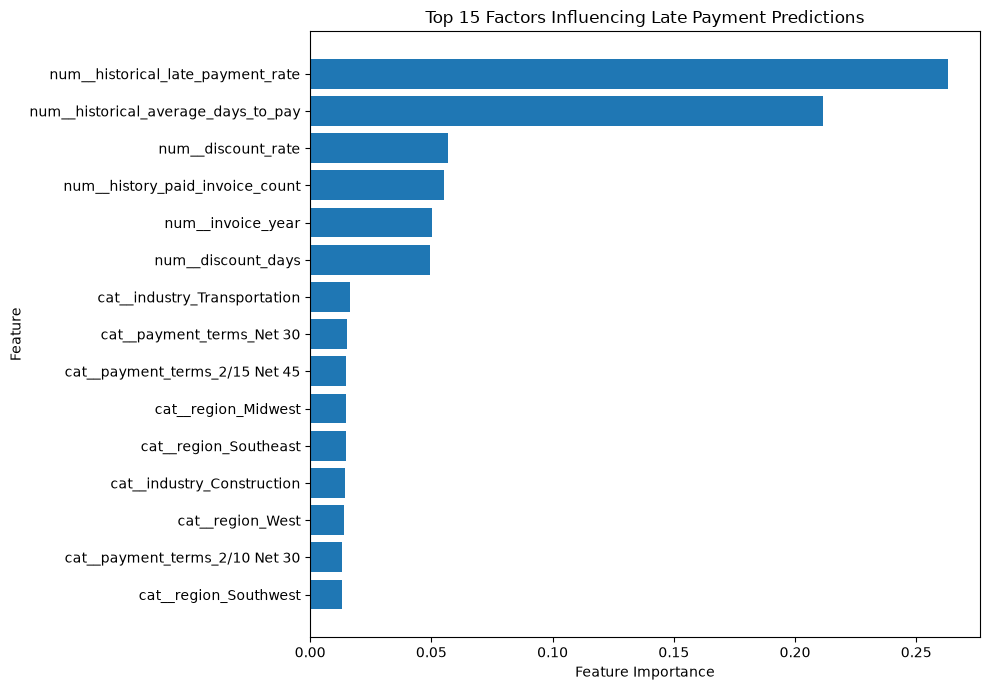

In [22]:
plt.figure(figsize=(10, 7))

top_features = feature_importance.head(15).sort_values(
    by="Importance"
)

plt.barh(top_features["Feature"], top_features["Importance"])

plt.title("Top 15 Factors Influencing Late Payment Predictions")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()